# TANE: my results vs. the paper
Compares my runs of the original TANE code (`results/all_results.csv`) with Tables 1 and 2 of Huhtala et al. (1999).

## 1. Libraries
pandas for tables, numpy for fitting a line, matplotlib for plots.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. The paper's numbers
Tables 1 and 2 typed in, one row per experiment, so my results can be matched against them (TANE/MEM times from Table 2).

In [3]:
paper = pd.DataFrame([
    # Table 1: TANE (disk version), exact dependencies
    ("lymphography",   "tane", 0, 2730, 68),
    ("hepatitis",      "tane", 0, 8250, 30),
    ("wisconsin_x1",   "tane", 0,   46, 1),
    ("wisconsin_x64",  "tane", 0,   46, 81),
    ("wisconsin_x128", "tane", 0,   46, 173),
    ("wisconsin_x512", "tane", 0,   46, 884),
    ("adult",          "tane", 0,   85, 1451),
    ("chess",          "tane", 0,    1, 4),
    # Table 2 (eps = 0) and Table 1 (x128): TANE/MEM, exact dependencies
    ("lymphography",   "tanemem", 0, 2730, 89.1),
    ("hepatitis",      "tanemem", 0, 8250, 16.6),
    ("wisconsin_x1",   "tanemem", 0,   46, 0.3),
    ("wisconsin_x2",   "tanemem", 0,   46, 0.5),
    ("wisconsin_x4",   "tanemem", 0,   46, 1.1),
    ("wisconsin_x8",   "tanemem", 0,   46, 2.4),
    ("wisconsin_x16",  "tanemem", 0,   46, 5.1),
    ("wisconsin_x32",  "tanemem", 0,   46, 11.0),
    ("wisconsin_x64",  "tanemem", 0,   46, 25.5),
    ("wisconsin_x128", "tanemem", 0,   46, 247),
    ("chess",          "tanemem", 0,    1, 2.0),
    # Table 2: approximate dependencies
    ("lymphography", "taneg3", 0.01, 3388, 22.2), ("lymphography", "taneg3", 0.05, 7031, 4.9),
    ("lymphography", "taneg3", 0.1,  6383, 3.7),  ("lymphography", "taneg3", 0.5,    21, 0.0),
    ("hepatitis",    "taneg3", 0.01, 9666, 14.6), ("hepatitis",    "taneg3", 0.05, 6617, 9.3),
    ("hepatitis",    "taneg3", 0.1,  2630, 4.2),  ("hepatitis",    "taneg3", 0.5,   160, 0.0),
    ("wisconsin_x1",  "taneg3", 0.01, 113, 0.3),  ("wisconsin_x1",  "taneg3", 0.05, 126, 0.2),
    ("wisconsin_x1",  "taneg3", 0.1,  141, 0.2),  ("wisconsin_x1",  "taneg3", 0.5,   18, 0.0),
    ("wisconsin_x2",  "taneg3", 0.01, 113, 0.5),  ("wisconsin_x2",  "taneg3", 0.05, 126, 0.5),
    ("wisconsin_x2",  "taneg3", 0.1,  141, 0.4),  ("wisconsin_x2",  "taneg3", 0.5,   18, 0.1),
    ("wisconsin_x4",  "taneg3", 0.01, 113, 1.1),  ("wisconsin_x4",  "taneg3", 0.05, 126, 1.0),
    ("wisconsin_x4",  "taneg3", 0.1,  141, 0.9),  ("wisconsin_x4",  "taneg3", 0.5,   18, 0.2),
    ("wisconsin_x8",  "taneg3", 0.01, 113, 2.3),  ("wisconsin_x8",  "taneg3", 0.05, 126, 2.0),
    ("wisconsin_x8",  "taneg3", 0.1,  141, 1.9),  ("wisconsin_x8",  "taneg3", 0.5,   18, 0.4),
    ("wisconsin_x16", "taneg3", 0.01, 113, 4.9),  ("wisconsin_x16", "taneg3", 0.05, 126, 4.4),
    ("wisconsin_x16", "taneg3", 0.1,  141, 4.3),  ("wisconsin_x16", "taneg3", 0.5,   18, 0.8),
    ("wisconsin_x32", "taneg3", 0.01, 113, 10.6), ("wisconsin_x32", "taneg3", 0.05, 126, 9.3),
    ("wisconsin_x32", "taneg3", 0.1,  141, 8.9),  ("wisconsin_x32", "taneg3", 0.5,   18, 1.8),
    ("wisconsin_x64", "taneg3", 0.01, 113, 26.7), ("wisconsin_x64", "taneg3", 0.05, 126, 20.3),
    ("wisconsin_x64", "taneg3", 0.1,  141, 19.2), ("wisconsin_x64", "taneg3", 0.5,   18, 3.9),
    ("chess", "taneg3", 0.01, 1, 2.6), ("chess", "taneg3", 0.05, 1, 3.1),
    ("chess", "taneg3", 0.1,  1, 3.5), ("chess", "taneg3", 0.5, 17, 3.6),
], columns=["dataset", "program", "epsilon", "paper_N", "paper_time"])

paper.head()

,dataset,program,epsilon,paper_N,paper_time
0,lymphography,tane,0.0,2730,68.0
1,hepatitis,tane,0.0,8250,30.0
2,wisconsin_x1,tane,0.0,46,1.0
3,wisconsin_x64,tane,0.0,46,81.0
4,wisconsin_x128,tane,0.0,46,173.0


## 3. My results
Loads my runs; `timeout` becomes NaN so the counts are numeric.

In [4]:
results = pd.read_csv("results/all_results.csv")
results = results[["dataset", "rows", "program", "epsilon", "deps_found", "seconds"]]
results["deps_found"] = pd.to_numeric(results["deps_found"], errors="coerce")

results.head()

,dataset,rows,program,epsilon,deps_found,seconds
0,lymphography,148,tanemem,0.00,2730,0.388
1,lymphography,148,tane,0.00,2730,0.781
2,lymphography,148,taneg3,0.01,3388,0.352
3,lymphography,148,taneg3,0.05,7031,0.093
4,lymphography,148,taneg3,0.10,6383,0.083


## 4. Side by side
Joins paper and my results per experiment: the number of dependencies must match exactly, while times only show the speed-up of a modern computer.

In [5]:
comparison = results.merge(paper, on=["dataset", "program", "epsilon"], how="left")

comparison["match"] = comparison["deps_found"] == comparison["paper_N"]
comparison["speedup"] = comparison["paper_time"] / comparison["seconds"]

comparison.to_csv("results/comparison.csv", index=False)
comparison

,dataset,rows,program,epsilon,deps_found,seconds,paper_N,paper_time,match,speedup
0,lymphography,148,tanemem,0.00,2730,0.388,2730.0,89.1,True,229.639175
1,lymphography,148,tane,0.00,2730,0.781,2730.0,68.0,True,87.067862
2,lymphography,148,taneg3,0.01,3388,0.352,3388.0,22.2,True,63.068182
3,lymphography,148,taneg3,0.05,7031,0.093,7031.0,4.9,True,52.688172
4,lymphography,148,taneg3,0.10,6383,0.083,6383.0,3.7,True,44.578313
...,...,...,...,...,...,...,...,...,...,...
63,chess,28056,tane,0.00,1,0.128,1.0,4.0,True,31.250000
64,chess,28056,taneg3,0.01,1,0.038,1.0,2.6,True,68.421053
65,chess,28056,taneg3,0.05,1,0.043,1.0,3.1,True,72.093023
66,chess,28056,taneg3,0.10,1,0.048,1.0,3.5,True,72.916667


## 5. Mismatches
Lists the experiments where my count differs from the paper.

In [6]:
reported = comparison["paper_N"].notna()
mismatches = comparison[reported & ~comparison["match"]]

print(len(comparison[reported]), "experiments reported in the paper,", len(mismatches), "mismatches")
mismatches

59 experiments reported in the paper, 6 mismatches


,dataset,rows,program,epsilon,deps_found,seconds,paper_N,paper_time,match,speedup
23,wisconsin_x2,1398,taneg3,0.5,82,0.019,18.0,0.1,False,5.263158
29,wisconsin_x4,2796,taneg3,0.5,82,0.017,18.0,0.2,False,11.764706
35,wisconsin_x8,5592,taneg3,0.5,82,0.016,18.0,0.4,False,25.000000
41,wisconsin_x16,11184,taneg3,0.5,82,0.023,18.0,0.8,False,34.782609
47,wisconsin_x32,22368,taneg3,0.5,82,0.030,18.0,1.8,False,60.000000
53,wisconsin_x64,44736,taneg3,0.5,82,0.050,18.0,3.9,False,78.000000


The only expected mismatches are Wisconsin × n (n ≥ 2) at ε = 0.5: copying splits frequent values, so dependencies with an empty left-hand side (e.g. ∅ → 10) no longer hold, and other dependencies become minimal (82 instead of 18).

## 6. Scaling (paper Figure 4)
Tests the paper's main claim of linear scaling: on a log-log plot linear growth is a line with slope 1, regardless of computer speed (runs under 5,000 rows are excluded from the fit because start-up time dominates).

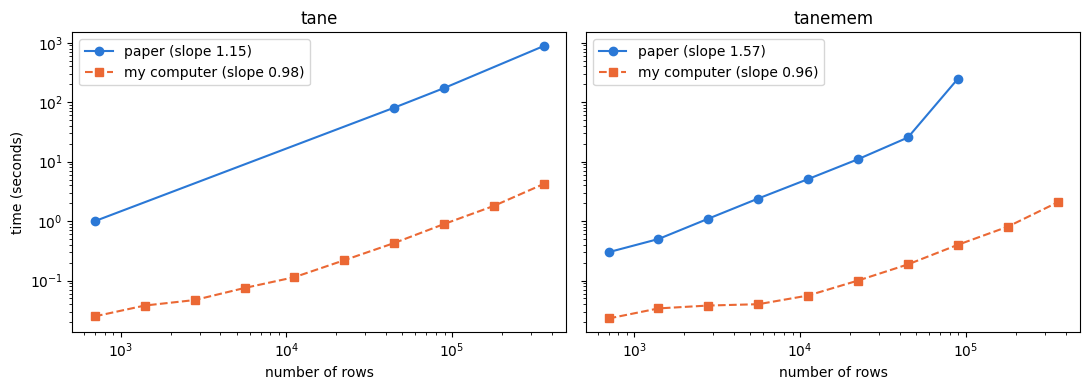

In [7]:
def slope(rows, seconds):
    keep = rows >= 5000
    return np.polyfit(np.log10(rows[keep]), np.log10(seconds[keep]), 1)[0]

wisconsin = comparison[comparison["dataset"].str.startswith("wisconsin") & (comparison["epsilon"] == 0)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, program in zip(axes, ["tane", "tanemem"]):
    mine = wisconsin[wisconsin["program"] == program]
    paper_points = mine.dropna(subset=["paper_time"])

    ax.loglog(paper_points["rows"], paper_points["paper_time"], "o-", color="#2a78d6",
              label=f"paper (slope {slope(paper_points['rows'], paper_points['paper_time']):.2f})")
    ax.loglog(mine["rows"], mine["seconds"], "s--", color="#eb6834",
              label=f"my computer (slope {slope(mine['rows'], mine['seconds']):.2f})")

    ax.set_title(program)
    ax.set_xlabel("number of rows")
    ax.legend()

axes[0].set_ylabel("time (seconds)")
plt.tight_layout()
plt.savefig("results/fig_scaling.png", dpi=200)
plt.show()

## 7. Effect of ε (paper Figure 3)
Dividing by the value at ε = 0 removes the computer speed, so the shape of the paper's curves can be compared directly.

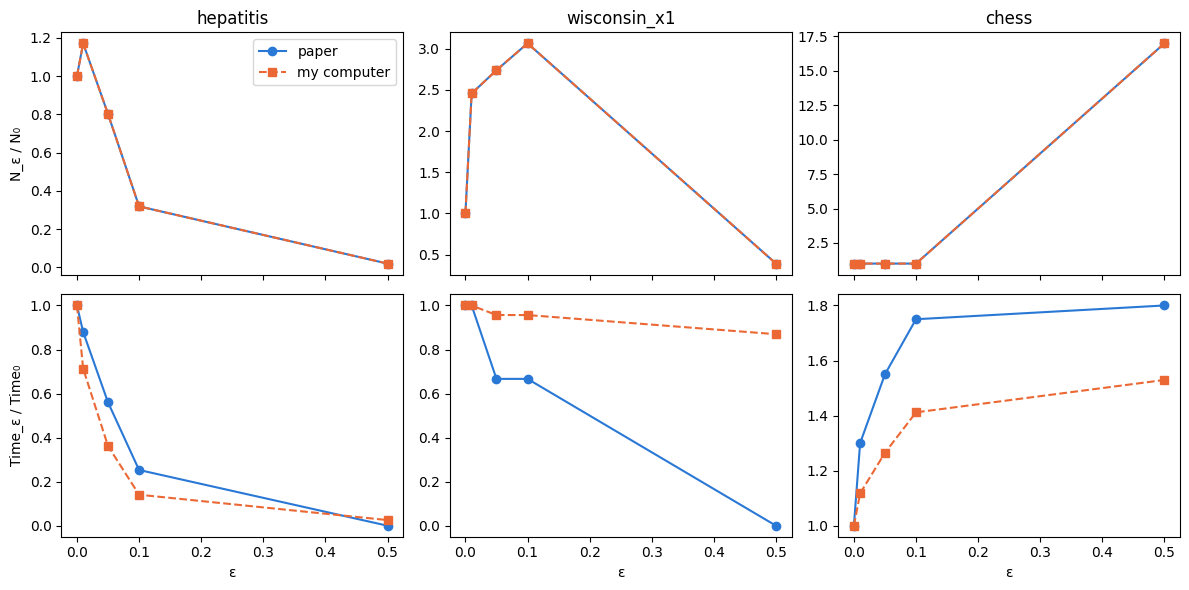

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)

for col, dataset in enumerate(["hepatitis", "wisconsin_x1", "chess"]):
    d = comparison[(comparison["dataset"] == dataset) & comparison["program"].isin(["tanemem", "taneg3"])]
    d = d.sort_values("epsilon")
    first = d.iloc[0]                                   # the row with epsilon = 0

    top, bottom = axes[0, col], axes[1, col]
    top.plot(d["epsilon"], d["paper_N"] / first["paper_N"], "o-", color="#2a78d6", label="paper")
    top.plot(d["epsilon"], d["deps_found"] / first["deps_found"], "s--", color="#eb6834", label="my computer")
    bottom.plot(d["epsilon"], d["paper_time"] / first["paper_time"], "o-", color="#2a78d6")
    bottom.plot(d["epsilon"], d["seconds"] / first["seconds"], "s--", color="#eb6834")

    top.set_title(dataset)
    bottom.set_xlabel("ε")

axes[0, 0].set_ylabel("N_ε / N₀")
axes[1, 0].set_ylabel("Time_ε / Time₀")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("results/fig_epsilon.png", dpi=200)
plt.show()

## 8. Why Wisconsin × 2 gives 82 instead of 18
At ε = 0.5 copying removes all dependencies with an empty left-hand side, so dependencies with one attribute on the left become minimal instead.

In [9]:
for dataset in ["wisconsin_x1", "wisconsin_x2"]:
    # 1. size of the left-hand side of each dependency found at eps = 0.5
    lines = open(f"results/logs/{dataset}_taneg3_eps0.5.log").read().splitlines()
    lhs_sizes = [len(line.split("->")[0].split()) for line in lines if "->" in line]
    print(dataset, "- dependencies per left-hand-side size:", pd.Series(lhs_sizes).value_counts().sort_index().to_dict())

    # 2. error of "empty -> A": fraction of rows NOT having the most frequent value of A
    data = pd.read_csv(f"data/{dataset}.dat", header=None)
    error = 1 - data.apply(lambda col: col.value_counts().iloc[0]) / len(data)
    print("   error of ∅ → A per attribute:", error.round(2).tolist())

wisconsin_x1 - dependencies per left-hand-side size: {0: 8, 1: 10}
   error of ∅ → A per attribute: [0.99, 0.79, 0.45, 0.49, 0.42, 0.45, 0.42, 0.76, 0.37, 0.17, 0.34]
wisconsin_x2 - dependencies per left-hand-side size: {1: 82}
   error of ∅ → A per attribute: [1.0, 0.9, 0.73, 0.75, 0.71, 0.72, 0.71, 0.88, 0.68, 0.59, 0.67]
